True `ftol` termination condition is satisfied.
ajustado: [2.4582049  4.00320656]
erro relativo: [0.01671804 0.02360816]
cost: 6.199520594355565
max|resíduo|: 1.8762925862434994
incertezas: [0.07523408 0.19269812]
pulls: [-0.5555341  -0.50230611]
chi2_red: 0.8856457991936522
correlação: -0.19351742423970097
cond(J): 2.6281092129639574


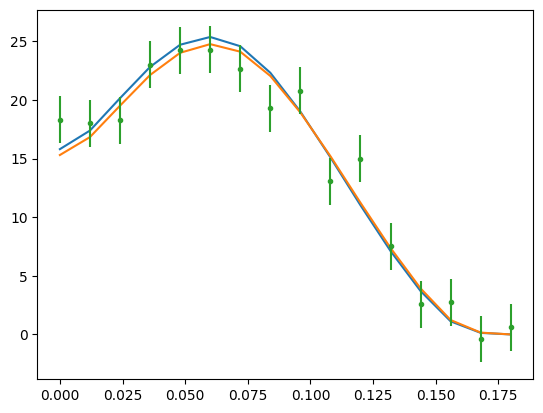

In [85]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy as sp
from scipy.optimize import least_squares

df_emissividade = pd.read_csv('Utilities/dados_esp.csv', sep = ',')
df_emissividade.head()

def onion_peeling_method(y_i):
    """
    Função implementa o método de Pearse, descrito por Dasch (1992), num conjunto de cordas y_i.

    Parâmetros:
    n_cordas (int): número de cordas a ser utilizado no experimento
    y_i (arr): malha criada com o número de cordas.

    Retorna:
    W_ij (arr): Matriz de pesos para o caso direto
    D_ij (arr): Matriz de deconvolução para a inversão através da inversão de W_ij
    """

    n_cordas = len(y_i)
    
    # Criação da malha 
    dr = y_i[1]-y_i[0]
    
    # Criação dos anéis utilizando o passo
    r_externo = y_i[:]+dr/2
    r_interno = y_i[:]-dr/2
    
    # Tratamento dos valores de borda
    r_externo[-1] = y_i[-1]+dr/2
    r_interno[0] = 0
    
    # Criando a matriz W_ij
    W_ij = np.zeros((n_cordas,n_cordas))
    
    # Preenchendo a matriz W_ij
    for i in range(0,n_cordas):
        for j in range(0,n_cordas):
            if r_externo[j] > abs(y_i[i]):
                W_ij[i,j] = 2*(np.sqrt(max(0,r_externo[j]**2-y_i[i]**2))-np.sqrt(max(0,r_interno[j]**2-y_i[i]**2)))
            else:
                W_ij[i,j] = 0
    
    D_ij = np.linalg.inv(W_ij)
    return W_ij, D_ij

def Vphi_model(t, DeltaV, gama, a=.18):
    """Calcula o modelo de sino da velocidade toroidal eliminando os valores imaginários e divisões por zero

    Parâmetros:
        t (float): Intervalos de valores de raio (m)
        DeltaV (float): Amplitude da velocidade (m/s)
        Gama (float):  Expoente efetivo
        a (float): raio maior do tokamak (m)
    Retorna:
        V_phi (arr): V_phi(t) simulada seguindo modelo descrito em Wesson J., Tokamaks (2004).
    """
    # Recusa valores de a negativos e iguais a 0
    if a <= 0:
        return print("Please insert the original Radius of your Tokamak")

    # Adapta o código para listas e números
    t = np.asarray(t)

    # Tratamento de possíveis valores negativos
    power = gama - 1
    base = 1 - (t/a)**2

    resultado = DeltaV * gama * (-2 * (t / a**2)) * (base**power)
    
    if power < 0:
        invalido = (base<=0)
    else:
        invalido = base<0
    
    return np.where(invalido,0.0,-1*resultado)

def Vapp(r, eps, Vphi):
    """Aplicação do modelo direto propagando a velocidade de plasma.

    Parâmetros:
        t (float): Valores de emissividade ao longo do raio.
        Vphi (float): Valores de velocidade toroidal ao longo do raio.
        W_ij (arr): Matriz de peso calculada utilizando o método de Onion Peeling.
    Retorna: 
        Vapp (arr): Curvas de valores de velocidade aparente.    
    """
    W_ij, D_ij = onion_peeling_method(r)
    
    U = W_ij @ (eps*Vphi)
    S = W_ij @ eps
    return U/S

r = np.linspace(0,0.18, 16)
eps = np.interp(r,df_emissividade['raio[m]'],df_emissividade['emissivity[fotonsm^-3s^-2'])

DeltaV = 2.5
gamma = 4.1

Vapp_simulado = Vapp(r, eps, Vphi_model(r,DeltaV,gamma))


Vapp_ruidoso = Vapp(r, eps, Vphi_model(r,DeltaV,gamma)) + np.random.normal(loc=0.0,scale = 2, size = len(r))
error = abs(Vapp_simulado-Vapp_ruidoso)

def residuos(params, r, eps,Vexp,Verr):
    DeltaV, gamma = params
    Vmodel = Vapp(r, eps, Vphi_model(r,DeltaV,gamma))
    return (Vexp - Vmodel)/Verr


y0 = [4,2]

ajuste = least_squares(residuos, x0 = y0, method = 'trf', args=(r, eps, Vapp_ruidoso,2.0))

ajuste.x

Vapp_ajustado = Vapp(r, eps, Vphi_model(r,*ajuste.x))

plt.plot(r, Vapp_simulado, label = 'Simulado')
plt.plot(r, Vapp_ajustado, label = 'ajuste')
plt.errorbar(r, Vapp_ruidoso, 2, fmt = 'o', ms = 3)

p_true = np.array([DeltaV, gamma])
print(ajuste.success, ajuste.message)
print("ajustado:", ajuste.x)
print("erro relativo:", np.abs(ajuste.x - p_true) / p_true)
print("cost:", ajuste.cost)
print("max|resíduo|:", np.max(np.abs(ajuste.fun)))
J = ajuste.jac
cov = np.linalg.inv(J.T @ J)
perr = np.sqrt(np.diag(cov))
p_true = np.array([2.5, 4.1])

print("incertezas:", perr)
print("pulls:", (ajuste.x - p_true) / perr)
print("chi2_red:", 2 * ajuste.cost / (len(r) - 2))
print("correlação:", cov[0, 1] / (perr[0] * perr[1]))
print("cond(J):", np.linalg.cond(J))

In [80]:
ajuste.x

array([2.61109336, 4.14228096])

In [81]:
chi2 = np.sum(ajuste.fun**2)

In [82]:
chi2/(len(r)-2)

0.8059337156735419

In [83]:
chi2

11.283072019429586